<a href="https://colab.research.google.com/github/maltraxis-lang/codex-ml-ps0/blob/main/cifar100_hyperparameter_tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CIFAR-100 Image Classification: Hyperparameter Tuning Challenge

Welcome! In this notebook you will train a small convolutional neural network (CNN) to recognise **100 kinds of objects** in tiny 32x32 colour images.

**Your mission is not just to run the code. It is to improve it.**

The model code is given to you. Your job is to change the **hyperparameters** (learning rate, batch size, dropout, and so on), run experiment after experiment, and keep a record of what worked and what did not, until you reach the best validation accuracy you can.

### How this notebook works
1. Run Steps 0 to 4 once, top to bottom (this gives you a baseline).
2. In Step 5, change **one hyperparameter at a time** and run again.
3. Every run is **logged automatically** into a results table (Step 6).
4. When you are happy with your best model, evaluate it **once** on the test set (Step 7).

> Tip: use **Runtime > Run all** the first time, then work cell by cell.

## Step 0: Set up (GPU)

Training on a CPU is very slow. Please switch to a free GPU:

**Runtime > Change runtime type > T4 GPU > Save**

Then run the cell below. You should see at least one GPU listed.

In [ ]:
import random, time, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# A fixed seed makes your results (mostly) repeatable, so comparisons between runs are fair.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPUs found:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPUs found: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 1: Load a SMALL version of CIFAR-100

The full CIFAR-100 (60,000 images, about 160 MB) can be slow or fail to download on Colab. So this notebook loads a **small slice** instead:

- It **streams** only the images it needs from the Hugging Face copy of CIFAR-100 (same data as on Kaggle), so the download is a fraction of the full size.
- It keeps only **NUM_CLASSES** of the 100 classes (20 by default), which also makes training much faster.
- If streaming fails, it automatically falls back to the normal Keras download and then slices it.

You can change the three size settings below. Bigger means more accurate but slower.

We split the data into three parts:

| Part | Used for |
|------|----------|
| Train | Teaching the model |
| Validation | **Comparing your experiments** (look at it as often as you like) |
| Test | The final exam. Use it **once**, at the very end. |

If you tune using the test set, your final score will be unfairly optimistic. That is called *data leakage*, so please resist the temptation.

In [ ]:
# ---------- Size settings for the short version (you may change these) ----------
NUM_CLASSES = 20      # how many of the 100 classes to keep (100 = all classes)
TRAIN_POOL = 20000    # images read from the original training set (max 50000)
TEST_POOL = 4000      # images read from the original test set (max 10000)
VAL_FRACTION = 0.15   # share of the kept training images used for validation
# Rough guide: images kept = TRAIN_POOL * NUM_CLASSES / 100 (so 20000 and 20 classes gives about 4000)

ALL_CLASS_NAMES = ['apple','aquarium_fish','baby','bear','beaver','bed','bee','beetle','bicycle','bottle',
 'bowl','boy','bridge','bus','butterfly','camel','can','castle','caterpillar','cattle',
 'chair','chimpanzee','clock','cloud','cockroach','couch','crab','crocodile','cup','dinosaur',
 'dolphin','elephant','flatfish','forest','fox','girl','hamster','house','kangaroo','keyboard',
 'lamp','lawn_mower','leopard','lion','lizard','lobster','man','maple_tree','motorcycle','mountain',
 'mouse','mushroom','oak_tree','orange','orchid','otter','palm_tree','pear','pickup_truck','pine_tree',
 'plain','plate','poppy','porcupine','possum','rabbit','raccoon','ray','road','rocket',
 'rose','sea','seal','shark','shrew','skunk','skyscraper','snail','snake','spider',
 'squirrel','streetcar','sunflower','sweet_pepper','table','tank','telephone','television','tiger','tractor',
 'train','trout','tulip','turtle','wardrobe','whale','willow_tree','wolf','woman','worm']
assert len(ALL_CLASS_NAMES) == 100


def load_stream(split, n):
    # Reads only n images from the Hugging Face copy of CIFAR-100 (small download)
    from datasets import load_dataset
    ds = load_dataset("uoft-cs/cifar100", split=split, streaming=True)
    ds = ds.shuffle(seed=SEED, buffer_size=10000)
    xs, ys = [], []
    for ex in ds.take(n):
        xs.append(np.array(ex["img"].convert("RGB"), dtype=np.uint8))
        ys.append(ex["fine_label"])
    return np.stack(xs), np.array(ys)


try:
    x_tr, y_tr = load_stream("train", TRAIN_POOL)
    x_te, y_te = load_stream("test", TEST_POOL)
    print("Loaded a small slice via Hugging Face streaming.")
except Exception as e:
    print("Streaming did not work (", repr(e)[:120], ").")
    print("Falling back to the Keras download (about 160 MB, one time only).")
    (xa, ya), (xb, yb) = keras.datasets.cifar100.load_data(label_mode="fine")
    r = np.random.RandomState(SEED)
    ia, ib = r.permutation(len(xa))[:TRAIN_POOL], r.permutation(len(xb))[:TEST_POOL]
    x_tr, y_tr, x_te, y_te = xa[ia], ya.flatten()[ia], xb[ib], yb.flatten()[ib]

# Keep only some classes, and renumber them 0 .. NUM_CLASSES-1
chosen = np.sort(np.random.RandomState(SEED).choice(100, NUM_CLASSES, replace=False))
remap = {int(c): i for i, c in enumerate(chosen)}
CLASS_NAMES = [ALL_CLASS_NAMES[c] for c in chosen]

def keep_classes(x, y):
    m = np.isin(y, chosen)
    return x[m], np.array([remap[int(c)] for c in y[m]])

x_tr, y_tr = keep_classes(x_tr, y_tr)
x_test, y_test = keep_classes(x_te, y_te)

# Train / validation split
perm = np.random.RandomState(SEED).permutation(len(x_tr))
n_val = int(len(x_tr) * VAL_FRACTION)
x_val, y_val = x_tr[perm[:n_val]], y_tr[perm[:n_val]]
x_train, y_train = x_tr[perm[n_val:]], y_tr[perm[n_val:]]

print(f"Classes: {NUM_CLASSES} | Train: {len(x_train)} | Validation: {len(x_val)} | Test: {len(x_test)}")
print("Classes kept:", CLASS_NAMES)
print("Random guessing would score about", f"{100 / NUM_CLASSES:.1f}%")

Loaded a small slice via Hugging Face streaming.
Classes: 20 | Train: 3391 | Validation: 598 | Test: 812
Classes kept: ['apple', 'beaver', 'bowl', 'bridge', 'caterpillar', 'clock', 'dolphin', 'elephant', 'forest', 'keyboard', 'lizard', 'lobster', 'orange', 'rose', 'shark', 'skyscraper', 'snail', 'squirrel', 'sweet_pepper', 'train']
Random guessing would score about 5.0%


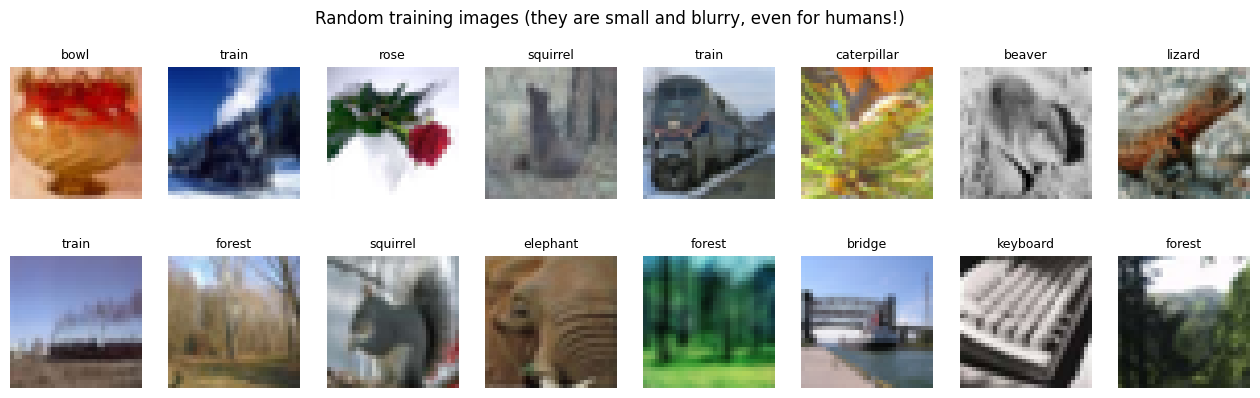

In [ ]:
# Take a look at some images
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, np.random.RandomState(0).choice(len(x_train), 16, replace=False)):
    ax.imshow(x_train[i])
    ax.set_title(CLASS_NAMES[y_train[i]], fontsize=9)
    ax.axis("off")
plt.suptitle("Random training images (they are small and blurry, even for humans!)")
plt.show()

## Step 2: The model (you do not need to edit this)

This function builds a CNN from a dictionary of settings called `cfg`. Each block has two convolution layers, batch normalisation, max pooling and dropout. The number of filters doubles after every block.

Read it, get curious about it, but all the tuning in this challenge happens through the `cfg` dictionary.

In [ ]:
def build_model(cfg):
    reg = keras.regularizers.l2(cfg["l2"]) if cfg["l2"] > 0 else None

    inputs = keras.Input(shape=(32, 32, 3))
    x = layers.Rescaling(1.0 / 255)(inputs)          # turn pixel values 0-255 into 0-1

    # Data augmentation: random changes to training images (only active while training)
    if cfg["augment"]:
        x = layers.RandomFlip("horizontal")(x)
        x = layers.RandomTranslation(0.1, 0.1)(x)
        x = layers.RandomRotation(0.05)(x)

    filters = cfg["base_filters"]
    for _ in range(cfg["num_blocks"]):
        for _ in range(2):
            x = layers.Conv2D(filters, 3, padding="same", use_bias=False, kernel_regularizer=reg)(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(cfg["dropout"])(x)
        filters *= 2

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(cfg["dense_units"], activation="relu", kernel_regularizer=reg)(x)
    x = layers.Dropout(cfg["dropout"])(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs)


def get_optimizer(cfg):
    name, lr = cfg["optimizer"].lower(), cfg["learning_rate"]
    if name == "adam":
        return keras.optimizers.Adam(learning_rate=lr)
    if name == "adamw":
        return keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-4)
    if name == "sgd":
        return keras.optimizers.SGD(learning_rate=lr, momentum=0.9, nesterov=True)
    if name == "rmsprop":
        return keras.optimizers.RMSprop(learning_rate=lr)
    raise ValueError("optimizer must be one of: adam, adamw, sgd, rmsprop")

## Step 3: The experiment runner (you do not need to edit this)

`run_experiment(cfg, notes)` does everything for one experiment:
- builds and trains the model with your settings,
- stops early if the model stops improving (saves time),
- plots the learning curves,
- **adds a row to your results table** and saves it to `experiment_log.csv`,
- keeps a copy of the best model so far in `best_model.keras`.

The `notes` text is for you: write what you changed and why.

In [ ]:
LOG_FILE, BEST_MODEL_FILE = "experiment_log.csv", "best_model.keras"

# Reload earlier results if the file exists (handy if you rerun this cell)
if os.path.exists(LOG_FILE):
    experiment_log = pd.read_csv(LOG_FILE).to_dict("records")
else:
    experiment_log = []
best_val_so_far = max([r["val_acc"] for r in experiment_log], default=0.0) if os.path.exists(BEST_MODEL_FILE) else 0.0


def make_ds(x, y, batch_size, training):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(len(x), seed=SEED)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


def plot_history(history, title):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
    a1.plot(history.history["loss"], label="train"); a1.plot(history.history["val_loss"], label="validation")
    a1.set_title("Loss (lower is better)"); a1.set_xlabel("epoch"); a1.legend()
    a2.plot(history.history["accuracy"], label="train"); a2.plot(history.history["val_accuracy"], label="validation")
    a2.set_title("Accuracy (higher is better)"); a2.set_xlabel("epoch"); a2.legend()
    fig.suptitle(title); plt.show()


def run_experiment(cfg, notes=""):
    global best_val_so_far
    keras.backend.clear_session()
    tf.random.set_seed(SEED)

    train_ds = make_ds(x_train, y_train, cfg["batch_size"], training=True)
    val_ds = make_ds(x_val, y_val, cfg["batch_size"], training=False)

    model = build_model(cfg)
    model.compile(optimizer=get_optimizer(cfg), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    callbacks = [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=cfg["patience"],
                                               restore_best_weights=True)]
    if cfg["use_lr_schedule"]:
        callbacks.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6))

    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=cfg["epochs"], callbacks=callbacks, verbose=2)
    minutes = (time.time() - start) / 60

    h = history.history
    best = int(np.argmax(h["val_accuracy"]))          # the epoch with the best validation accuracy
    row = {"run": len(experiment_log) + 1, "notes": notes}
    row.update(cfg)
    row.update({
        "train_acc": round(h["accuracy"][best], 4),
        "val_acc": round(h["val_accuracy"][best], 4),
        "val_loss": round(h["val_loss"][best], 4),
        "gap": round(h["accuracy"][best] - h["val_accuracy"][best], 4),   # big gap = overfitting
        "best_epoch": best + 1,
        "epochs_run": len(h["loss"]),
        "minutes": round(minutes, 1),
        "params": model.count_params(),
    })
    experiment_log.append(row)
    pd.DataFrame(experiment_log).to_csv(LOG_FILE, index=False)

    if row["val_acc"] > best_val_so_far:
        best_val_so_far = row["val_acc"]
        model.save(BEST_MODEL_FILE)
        print("New best model saved!")

    plot_history(history, f"Run {row['run']}: {notes}")
    print(f"Run {row['run']} | val_acc = {row['val_acc']:.4f} | train_acc = {row['train_acc']:.4f} | "
          f"gap = {row['gap']:.4f} | {row['minutes']} min")
    return model

## Step 4: Baseline run

This is the starting point. It uses reasonable but un-tuned settings. Run it and note the validation accuracy. **This is the number you are trying to beat.**

Here is what each setting means:

| Setting | Meaning |
|---------|---------|
| `learning_rate` | How big a step the model takes when learning. Too high: unstable. Too low: very slow. |
| `batch_size` | How many images are used for each update. |
| `epochs` | Maximum passes over the training data (early stopping may end sooner). |
| `optimizer` | The learning algorithm: `adam`, `adamw`, `sgd`, `rmsprop`. |
| `dropout` | Fraction of neurons randomly switched off while training (fights overfitting). |
| `l2` | Weight penalty (fights overfitting). `0` means off. |
| `base_filters` | Width of the first conv layer. It doubles each block. Bigger = more capacity. |
| `num_blocks` | Depth of the network (1 to 4). |
| `dense_units` | Size of the fully connected layer before the output. |
| `augment` | `True` randomly flips, shifts and rotates training images. |
| `use_lr_schedule` | `True` halves the learning rate when progress stalls. |
| `patience` | Epochs to wait without improvement before stopping early. |

Epoch 1/30
53/53 - 33s - 622ms/step - accuracy: 0.1908 - loss: 2.5665 - val_accuracy: 0.0769 - val_loss: 2.9889
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2707 - loss: 2.2385 - val_accuracy: 0.0602 - val_loss: 3.2927
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.3170 - loss: 2.1107 - val_accuracy: 0.1137 - val_loss: 3.7122
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.3568 - loss: 1.9794 - val_accuracy: 0.1221 - val_loss: 3.7298
Epoch 5/30
53/53 - 0s - 9ms/step - accuracy: 0.3875 - loss: 1.9156 - val_accuracy: 0.0652 - val_loss: 3.8444
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.4220 - loss: 1.7908 - val_accuracy: 0.1355 - val_loss: 4.2518
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.4329 - loss: 1.7322 - val_accuracy: 0.1355 - val_loss: 3.7031
Epoch 8/30
53/53 - 1s - 11ms/step - accuracy: 0.4645 - loss: 1.6419 - val_accuracy: 0.1756 - val_loss: 3.2858
Epoch 9/30
53/53 - 1s - 9ms/step - accuracy: 0.4825 - loss: 1.5920 - val_accuracy: 0.2308 - val_loss: 2.8913
Epoch 10/3

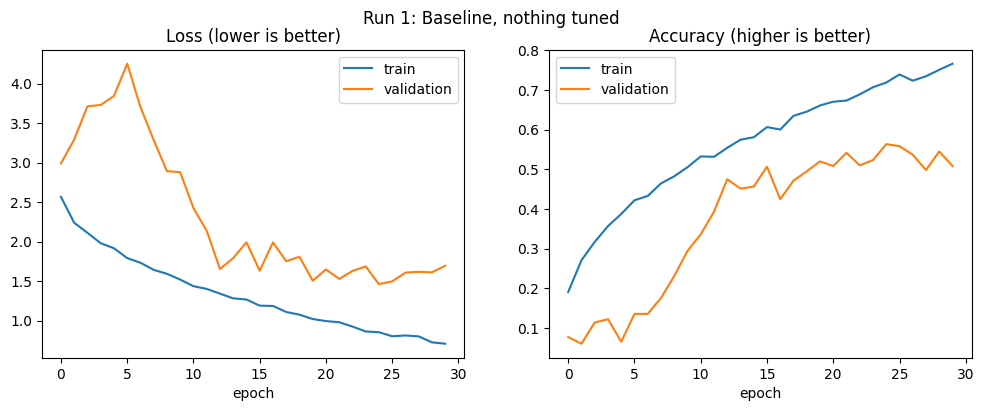

Run 1 | val_acc = 0.5635 | train_acc = 0.7190 | gap = 0.1554 | 0.8 min


In [ ]:
baseline_cfg = {
    "learning_rate": 0.001,
    "batch_size": 64,
    "epochs": 30,
    "optimizer": "adam",
    "dropout": 0.25,
    "l2": 0.0,
    "base_filters": 32,
    "num_blocks": 3,
    "dense_units": 256,
    "augment": False,
    "use_lr_schedule": False,
    "patience": 6,
}

model = run_experiment(baseline_cfg, notes="Baseline, nothing tuned")

## Step 5: YOUR TURN, run experiments

### The golden rule: change ONE thing at a time
If you change three settings and the score goes up, you will not know which change helped.

### The loop
1. Look at the learning curves and the `gap` column from your last run.
2. Form a guess ("The model is overfitting, so more dropout might help").
3. Copy your best config, change **one** value, and write a clear `notes` message.
4. Run it. Check the table in Step 6. Repeat.

### Reading the curves
| What you see | What it probably means | Things to try |
|--------------|------------------------|---------------|
| Train and validation accuracy both low | Underfitting | Bigger model (`base_filters`, `num_blocks`), higher learning rate, train longer |
| Train accuracy high, validation much lower (large `gap`) | Overfitting | `augment=True`, more `dropout`, `l2` > 0, smaller model |
| Validation loss jumps around wildly | Learning rate too high | Lower `learning_rate`, `use_lr_schedule=True` |
| Training is very slow to improve | Learning rate too low | Raise `learning_rate` |
| Stops early at a poor score | `patience` too small | Increase `patience` and `epochs` |

### Ideas for a good search order
1. `augment` (usually a big win on CIFAR-100)
2. `learning_rate` (try 0.01, 0.003, 0.0003)
3. `dropout` (0.1, 0.3, 0.4, 0.5)
4. `use_lr_schedule` and a larger `epochs`
5. Model size: `base_filters` (64) and `num_blocks`
6. `batch_size` (32, 128) and `optimizer`
7. Finally, combine the good ideas and fine-tune around them

Below is a template. Edit the lines marked with `# CHANGE`.

Epoch 1/30
53/53 - 18s - 331ms/step - accuracy: 0.1943 - loss: 2.5549 - val_accuracy: 0.0786 - val_loss: 3.0056
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2678 - loss: 2.2331 - val_accuracy: 0.1120 - val_loss: 3.3177
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.3200 - loss: 2.1147 - val_accuracy: 0.1154 - val_loss: 3.5351
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.3577 - loss: 1.9929 - val_accuracy: 0.1656 - val_loss: 3.2669
Epoch 5/30
53/53 - 0s - 9ms/step - accuracy: 0.3899 - loss: 1.8793 - val_accuracy: 0.1589 - val_loss: 3.1880
Epoch 6/30
53/53 - 0s - 9ms/step - accuracy: 0.4099 - loss: 1.7983 - val_accuracy: 0.1304 - val_loss: 4.5767
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.4409 - loss: 1.7224 - val_accuracy: 0.1789 - val_loss: 3.2987
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.4571 - loss: 1.6282 - val_accuracy: 0.2207 - val_loss: 3.1166
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.4845 - loss: 1.5919 - val_accuracy: 0.3328 - val_loss: 2.2664
Epoch 10/3

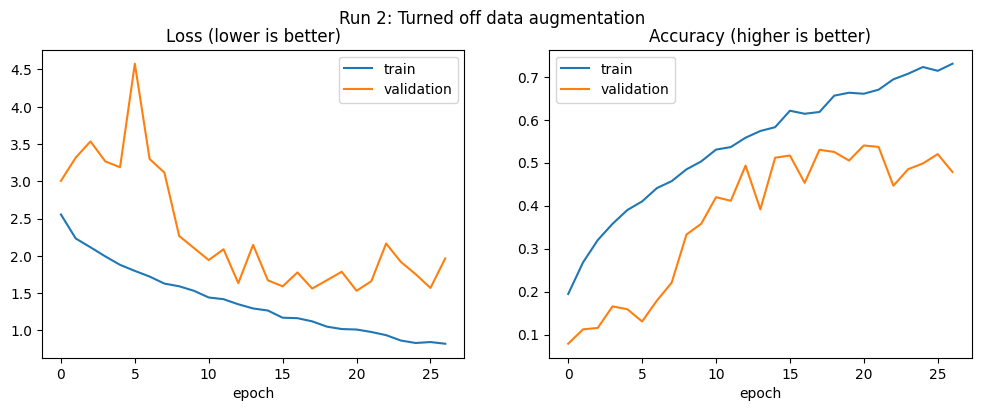

Run 2 | val_acc = 0.5401 | train_acc = 0.6606 | gap = 0.1204 | 0.5 min


In [ ]:
# Experiment 2: copy of the baseline with ONE change
cfg = dict(baseline_cfg)            # start from a known config
cfg["augment"] = False              # CHANGE: the one thing you are testing

model = run_experiment(cfg, notes="Turned off data augmentation")

Epoch 1/30
53/53 - 17s - 330ms/step - accuracy: 0.2058 - loss: 2.5352 - val_accuracy: 0.0368 - val_loss: 3.1947
Epoch 2/30
53/53 - 7s - 123ms/step - accuracy: 0.2802 - loss: 2.2103 - val_accuracy: 0.1020 - val_loss: 3.2315
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.3158 - loss: 2.1160 - val_accuracy: 0.1171 - val_loss: 3.6610
Epoch 4/30
53/53 - 0s - 9ms/step - accuracy: 0.3350 - loss: 2.0237 - val_accuracy: 0.0970 - val_loss: 3.8078
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.3683 - loss: 1.9255 - val_accuracy: 0.1237 - val_loss: 3.6984
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.4143 - loss: 1.8190 - val_accuracy: 0.1472 - val_loss: 4.1565
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.4191 - loss: 1.7539 - val_accuracy: 0.2157 - val_loss: 3.1579
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.4527 - loss: 1.6825 - val_accuracy: 0.2726 - val_loss: 2.5425
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.4795 - loss: 1.6147 - val_accuracy: 0.3094 - val_loss: 2.3436
Epoch 10

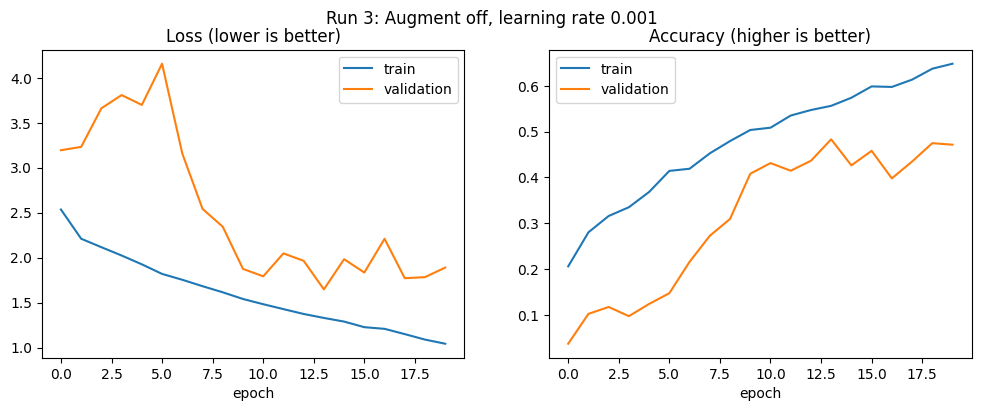

Run 3 | val_acc = 0.4833 | train_acc = 0.5565 | gap = 0.0732 | 0.6 min


In [ ]:
# Experiment 3: build on whatever worked best so far
cfg = dict(baseline_cfg)              # keep what helped
cfg["learning_rate"] = 0.001       # CHANGE: the new thing you are testing

model = run_experiment(cfg, notes="Augment off, learning rate 0.001")

Epoch 1/30
53/53 - 18s - 330ms/step - accuracy: 0.1787 - loss: 2.5647 - val_accuracy: 0.0819 - val_loss: 3.0677
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2518 - loss: 2.2707 - val_accuracy: 0.0769 - val_loss: 3.3424
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.3058 - loss: 2.1499 - val_accuracy: 0.0953 - val_loss: 3.9772
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.3291 - loss: 2.0447 - val_accuracy: 0.0886 - val_loss: 4.0279
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.3542 - loss: 1.9542 - val_accuracy: 0.1405 - val_loss: 3.5441
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.3969 - loss: 1.8492 - val_accuracy: 0.1455 - val_loss: 3.5150
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.4188 - loss: 1.7853 - val_accuracy: 0.2007 - val_loss: 3.0730
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.4447 - loss: 1.6937 - val_accuracy: 0.2241 - val_loss: 2.9511
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.4559 - loss: 1.6529 - val_accuracy: 0.2157 - val_loss: 2.9878
Epoch 10

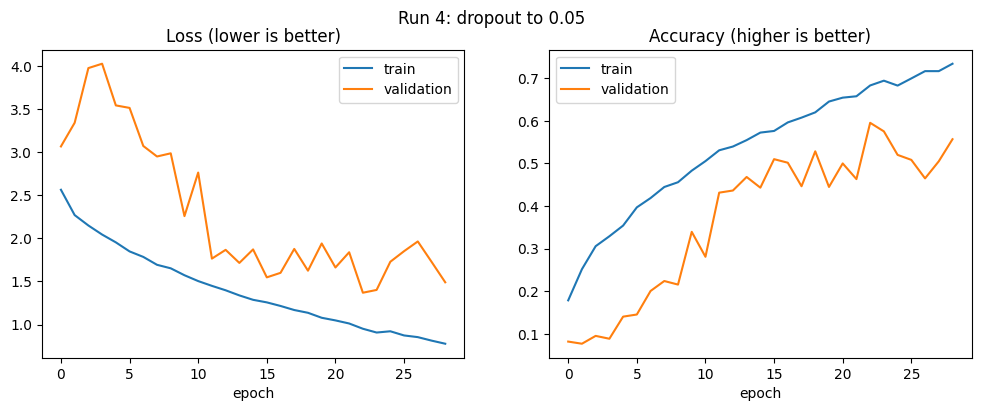

Run 4 | val_acc = 0.5953 | train_acc = 0.6830 | gap = 0.0877 | 0.5 min


In [ ]:
# Experiment 4: copy this cell as many times as you need (use the + Code button)
cfg = dict(baseline_cfg)
cfg["dropout"] =  0.25                 # CHANGE

model = run_experiment(cfg, notes="dropout to 0.05")

Epoch 1/30
53/53 - 17s - 330ms/step - accuracy: 0.1911 - loss: 2.5746 - val_accuracy: 0.0652 - val_loss: 3.0498
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2834 - loss: 2.2399 - val_accuracy: 0.0468 - val_loss: 3.5194
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.3206 - loss: 2.1146 - val_accuracy: 0.1171 - val_loss: 3.6501
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.3542 - loss: 1.9995 - val_accuracy: 0.1154 - val_loss: 4.0019
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.3677 - loss: 1.9484 - val_accuracy: 0.0836 - val_loss: 4.4588
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.3999 - loss: 1.8341 - val_accuracy: 0.1438 - val_loss: 3.7818
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.4308 - loss: 1.7629 - val_accuracy: 0.1522 - val_loss: 3.5421
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.4595 - loss: 1.6757 - val_accuracy: 0.1756 - val_loss: 3.6618
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.4659 - loss: 1.6426 - val_accuracy: 0.2458 - val_loss: 2.7172
Epoch 10

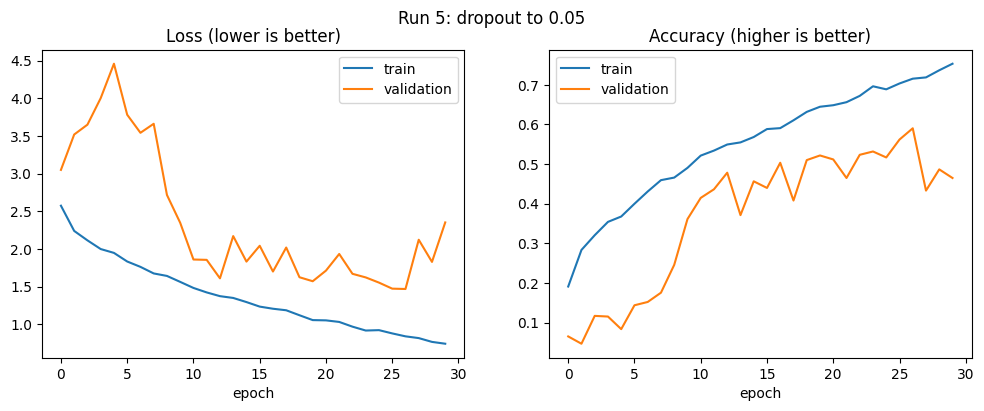

Run 5 | val_acc = 0.5903 | train_acc = 0.7154 | gap = 0.1251 | 0.5 min


In [ ]:
# Experiment 4: copy this cell as many times as you need (use the + Code button)
cfg = dict(baseline_cfg)
cfg["batch_size"] = 64              # CHANGE #"batch_size": 64

model = run_experiment(cfg, notes="dropout to 0.05")

Epoch 1/30
53/53 - 17s - 329ms/step - accuracy: 0.1864 - loss: 2.5628 - val_accuracy: 0.1104 - val_loss: 2.9272
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2598 - loss: 2.2621 - val_accuracy: 0.0502 - val_loss: 3.2818
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.2858 - loss: 2.1714 - val_accuracy: 0.0652 - val_loss: 3.3583
Epoch 4/30
53/53 - 0s - 9ms/step - accuracy: 0.3326 - loss: 2.0557 - val_accuracy: 0.0769 - val_loss: 3.5418
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.3468 - loss: 2.0048 - val_accuracy: 0.1154 - val_loss: 3.4184
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.3854 - loss: 1.8830 - val_accuracy: 0.1304 - val_loss: 3.5576
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.4096 - loss: 1.8244 - val_accuracy: 0.2057 - val_loss: 2.8637
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.4288 - loss: 1.7521 - val_accuracy: 0.2274 - val_loss: 2.6019
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.4571 - loss: 1.6895 - val_accuracy: 0.3060 - val_loss: 2.3829
Epoch 10/

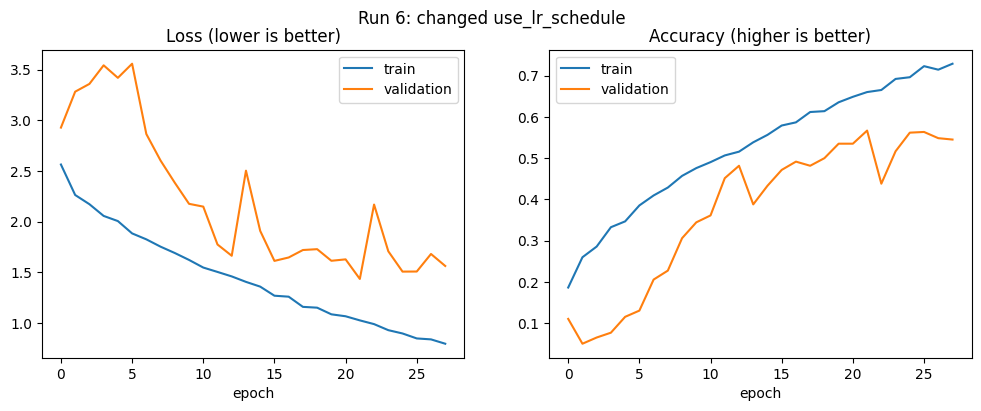

Run 6 | val_acc = 0.5669 | train_acc = 0.6603 | gap = 0.0934 | 0.5 min


In [ ]:
# Experiment 4: copy this cell as many times as you need (use the + Code button)
cfg = dict(baseline_cfg)
cfg["use_lr_schedule"] = False             # CHANGE #"batch_size": 64

model = run_experiment(cfg, notes="changed use_lr_schedule")

Epoch 1/30
53/53 - 18s - 331ms/step - accuracy: 0.1881 - loss: 2.5812 - val_accuracy: 0.0619 - val_loss: 3.1468
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2672 - loss: 2.2700 - val_accuracy: 0.0468 - val_loss: 3.6941
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.2908 - loss: 2.1613 - val_accuracy: 0.0502 - val_loss: 3.7375
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.3194 - loss: 2.0437 - val_accuracy: 0.0786 - val_loss: 3.6461
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.3654 - loss: 1.9641 - val_accuracy: 0.0753 - val_loss: 3.6825
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.4019 - loss: 1.8540 - val_accuracy: 0.1438 - val_loss: 3.4162
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.4182 - loss: 1.7895 - val_accuracy: 0.1722 - val_loss: 3.2009
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.4485 - loss: 1.6982 - val_accuracy: 0.1906 - val_loss: 2.9988
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.4745 - loss: 1.6333 - val_accuracy: 0.2425 - val_loss: 2.7102
Epoch 10

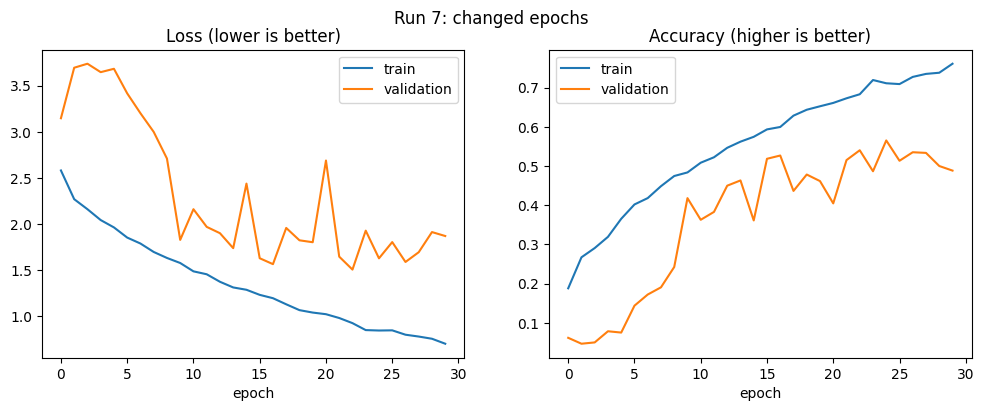

Run 7 | val_acc = 0.5652 | train_acc = 0.7110 | gap = 0.1458 | 0.5 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["epochs"]   = 30         # CHANGE #"batch_size": 64

model = run_experiment(cfg, notes="changed epochs")

Epoch 1/30
53/53 - 18s - 331ms/step - accuracy: 0.1710 - loss: 2.5954 - val_accuracy: 0.0619 - val_loss: 3.0676
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2536 - loss: 2.2821 - val_accuracy: 0.0619 - val_loss: 3.3737
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.3029 - loss: 2.1577 - val_accuracy: 0.1020 - val_loss: 3.5416
Epoch 4/30
53/53 - 1s - 12ms/step - accuracy: 0.3409 - loss: 2.0281 - val_accuracy: 0.1254 - val_loss: 3.5120
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.3760 - loss: 1.9407 - val_accuracy: 0.1154 - val_loss: 3.5024
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.3931 - loss: 1.8601 - val_accuracy: 0.1706 - val_loss: 3.4300
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.4258 - loss: 1.7676 - val_accuracy: 0.1739 - val_loss: 3.2445
Epoch 8/30
53/53 - 1s - 9ms/step - accuracy: 0.4450 - loss: 1.6776 - val_accuracy: 0.1622 - val_loss: 3.2520
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.4766 - loss: 1.6156 - val_accuracy: 0.2692 - val_loss: 2.5989
Epoch 10/

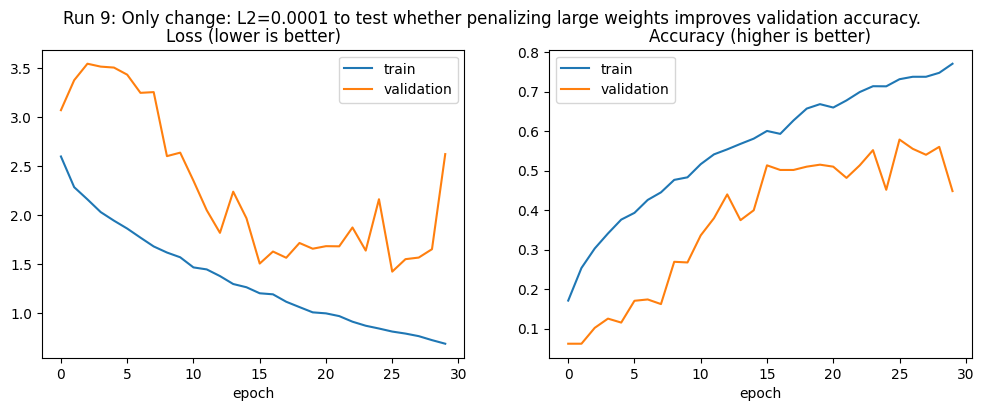

Run 9 | val_acc = 0.5786 | train_acc = 0.7313 | gap = 0.1528 | 0.6 min


In [ ]:
cfg["l2"] = 0.0

model = run_experiment(
    cfg,
    notes="Only change: L2=0.0001 to test whether penalizing large weights improves validation accuracy."
)

Epoch 1/30
53/53 - 28s - 533ms/step - accuracy: 0.1879 - loss: 2.5838 - val_accuracy: 0.0652 - val_loss: 3.2947
Epoch 2/30
53/53 - 1s - 17ms/step - accuracy: 0.2545 - loss: 2.2792 - val_accuracy: 0.0652 - val_loss: 3.6864
Epoch 3/30
53/53 - 1s - 16ms/step - accuracy: 0.3102 - loss: 2.1303 - val_accuracy: 0.1120 - val_loss: 4.2990
Epoch 4/30
53/53 - 1s - 21ms/step - accuracy: 0.3468 - loss: 2.0129 - val_accuracy: 0.1070 - val_loss: 4.7812
Epoch 5/30
53/53 - 1s - 20ms/step - accuracy: 0.3642 - loss: 1.9390 - val_accuracy: 0.1288 - val_loss: 4.1182
Epoch 6/30
53/53 - 1s - 16ms/step - accuracy: 0.4084 - loss: 1.8326 - val_accuracy: 0.1371 - val_loss: 3.8826
Epoch 7/30
53/53 - 1s - 17ms/step - accuracy: 0.4282 - loss: 1.7400 - val_accuracy: 0.1555 - val_loss: 3.3885
Epoch 8/30
53/53 - 1s - 16ms/step - accuracy: 0.4692 - loss: 1.6429 - val_accuracy: 0.1538 - val_loss: 3.9143
Epoch 9/30
53/53 - 1s - 16ms/step - accuracy: 0.4892 - loss: 1.5595 - val_accuracy: 0.2425 - val_loss: 2.8992
Epoch 10

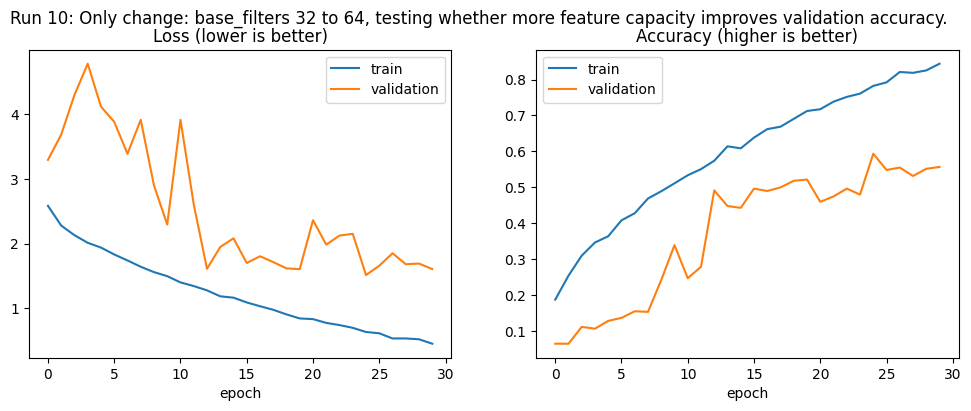

Run 10 | val_acc = 0.5936 | train_acc = 0.7824 | gap = 0.1887 | 0.9 min


In [ ]:
cfg["base_filters"] = 64

model = run_experiment(
    cfg,
    notes="Only change: base_filters 32 to 64, testing whether more feature capacity improves validation accuracy."
)

Epoch 1/30
53/53 - 17s - 322ms/step - accuracy: 0.1994 - loss: 2.5246 - val_accuracy: 0.0753 - val_loss: 3.0678
Epoch 2/30
53/53 - 1s - 18ms/step - accuracy: 0.2684 - loss: 2.2379 - val_accuracy: 0.0635 - val_loss: 3.6815
Epoch 3/30
53/53 - 1s - 19ms/step - accuracy: 0.3147 - loss: 2.1131 - val_accuracy: 0.1070 - val_loss: 3.9909
Epoch 4/30
53/53 - 1s - 21ms/step - accuracy: 0.3530 - loss: 1.9986 - val_accuracy: 0.1020 - val_loss: 4.1520
Epoch 5/30
53/53 - 1s - 19ms/step - accuracy: 0.3922 - loss: 1.8829 - val_accuracy: 0.1522 - val_loss: 3.6208
Epoch 6/30
53/53 - 1s - 21ms/step - accuracy: 0.4332 - loss: 1.7576 - val_accuracy: 0.2074 - val_loss: 3.5331
Epoch 7/30
53/53 - 1s - 16ms/step - accuracy: 0.4665 - loss: 1.6586 - val_accuracy: 0.1756 - val_loss: 3.5350
Epoch 8/30
53/53 - 1s - 17ms/step - accuracy: 0.4866 - loss: 1.5709 - val_accuracy: 0.2157 - val_loss: 2.9018
Epoch 9/30
53/53 - 1s - 17ms/step - accuracy: 0.5184 - loss: 1.4890 - val_accuracy: 0.2759 - val_loss: 2.6548
Epoch 10

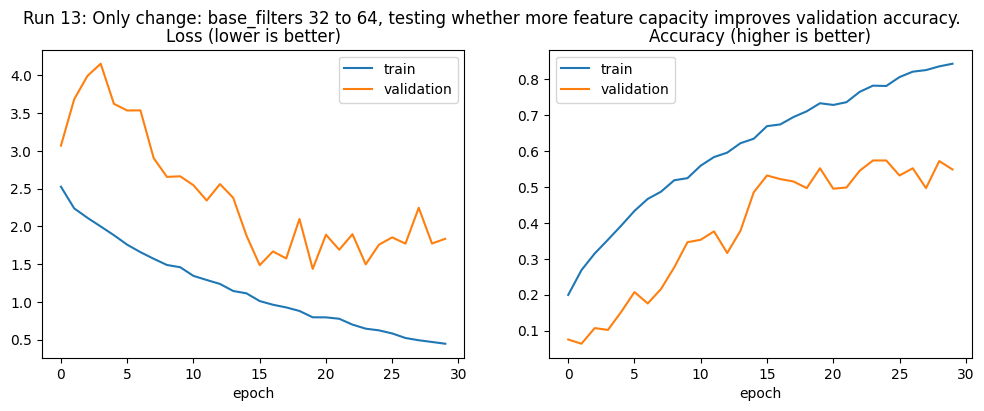

Run 13 | val_acc = 0.5736 | train_acc = 0.7818 | gap = 0.2082 | 0.7 min


In [ ]:
cfg["dense_units"] = 256    #dense_units=128
model = run_experiment(
    cfg,
    notes="Only change: base_filters 32 to 64, testing whether more feature capacity improves validation accuracy."
)

Epoch 1/30
53/53 - 17s - 316ms/step - accuracy: 0.1935 - loss: 2.6003 - val_accuracy: 0.1120 - val_loss: 3.0552
Epoch 2/30
53/53 - 1s - 17ms/step - accuracy: 0.2669 - loss: 2.2571 - val_accuracy: 0.0619 - val_loss: 3.2603
Epoch 3/30
53/53 - 1s - 16ms/step - accuracy: 0.3141 - loss: 2.1389 - val_accuracy: 0.0602 - val_loss: 4.0096
Epoch 4/30
53/53 - 1s - 16ms/step - accuracy: 0.3648 - loss: 1.9971 - val_accuracy: 0.0736 - val_loss: 4.7284
Epoch 5/30
53/53 - 1s - 16ms/step - accuracy: 0.4014 - loss: 1.8917 - val_accuracy: 0.1087 - val_loss: 3.4617
Epoch 6/30
53/53 - 1s - 17ms/step - accuracy: 0.4146 - loss: 1.8122 - val_accuracy: 0.1154 - val_loss: 4.4888
Epoch 7/30
53/53 - 1s - 17ms/step - accuracy: 0.4459 - loss: 1.7028 - val_accuracy: 0.1622 - val_loss: 3.6203
Epoch 8/30
53/53 - 1s - 17ms/step - accuracy: 0.4825 - loss: 1.6105 - val_accuracy: 0.2241 - val_loss: 3.0769
Epoch 9/30
53/53 - 1s - 17ms/step - accuracy: 0.4966 - loss: 1.5688 - val_accuracy: 0.2709 - val_loss: 2.4818
Epoch 10

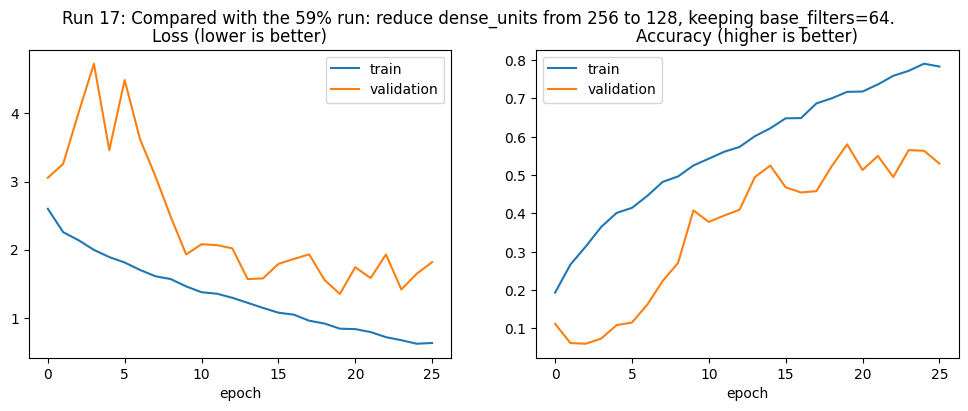

Run 17 | val_acc = 0.5803 | train_acc = 0.7172 | gap = 0.1369 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["base_filters"] = 64
cfg["dense_units"] = 128

model = run_experiment(
    cfg,
    notes="Compared with the 59% run: reduce dense_units from 256 to 128, keeping base_filters=64."
)

{'learning_rate': 0.001, 'batch_size': 64, 'epochs': 30, 'optimizer': 'adam', 'dropout': 0.1, 'l2': 0.0, 'base_filters': 64, 'num_blocks': 3, 'dense_units': 128, 'augment': False, 'use_lr_schedule': False, 'patience': 6}
Epoch 1/30
53/53 - 17s - 321ms/step - accuracy: 0.2047 - loss: 2.5253 - val_accuracy: 0.1003 - val_loss: 3.1885
Epoch 2/30
53/53 - 1s - 18ms/step - accuracy: 0.2849 - loss: 2.1990 - val_accuracy: 0.0870 - val_loss: 3.5182
Epoch 3/30
53/53 - 1s - 16ms/step - accuracy: 0.3403 - loss: 2.0440 - val_accuracy: 0.0886 - val_loss: 3.9391
Epoch 4/30
53/53 - 1s - 17ms/step - accuracy: 0.3834 - loss: 1.8878 - val_accuracy: 0.1187 - val_loss: 3.8374
Epoch 5/30
53/53 - 1s - 17ms/step - accuracy: 0.4152 - loss: 1.7890 - val_accuracy: 0.1789 - val_loss: 3.1178
Epoch 6/30
53/53 - 1s - 16ms/step - accuracy: 0.4665 - loss: 1.6448 - val_accuracy: 0.1605 - val_loss: 3.9830
Epoch 7/30
53/53 - 1s - 16ms/step - accuracy: 0.5066 - loss: 1.5116 - val_accuracy: 0.1789 - val_loss: 3.4962
Epoch 8

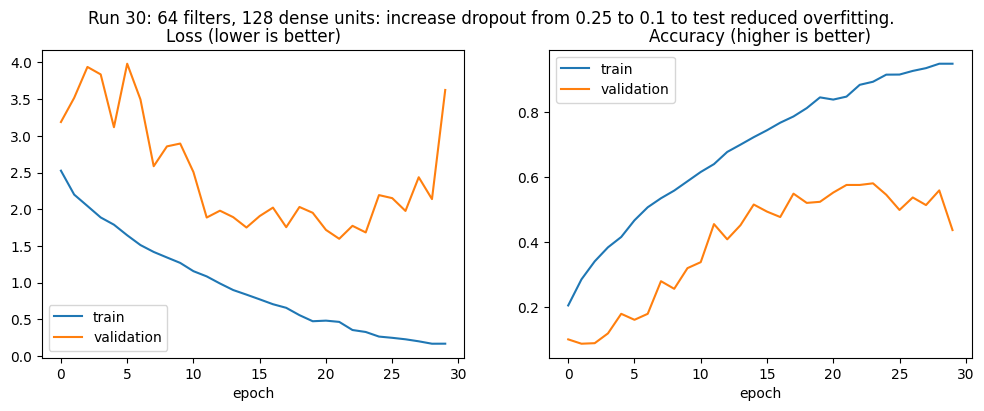

Run 30 | val_acc = 0.5803 | train_acc = 0.8927 | gap = 0.3124 | 0.7 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["base_filters"] = 64
cfg["dense_units"] = 128
cfg["dropout"] = 0.1

print(cfg)

model = run_experiment(
    cfg,
    notes="64 filters, 128 dense units: increase dropout from 0.25 to 0.1 to test reduced overfitting."
)

Epoch 1/30
53/53 - 18s - 331ms/step - accuracy: 0.2005 - loss: 2.5501 - val_accuracy: 0.1003 - val_loss: 2.9730
Epoch 2/30
53/53 - 1s - 17ms/step - accuracy: 0.2772 - loss: 2.2315 - val_accuracy: 0.0669 - val_loss: 3.3956
Epoch 3/30
53/53 - 1s - 17ms/step - accuracy: 0.3182 - loss: 2.1088 - val_accuracy: 0.1221 - val_loss: 3.5638
Epoch 4/30
53/53 - 1s - 16ms/step - accuracy: 0.3701 - loss: 1.9340 - val_accuracy: 0.1087 - val_loss: 3.5875
Epoch 5/30
53/53 - 1s - 16ms/step - accuracy: 0.3987 - loss: 1.8448 - val_accuracy: 0.1204 - val_loss: 3.8473
Epoch 6/30
53/53 - 1s - 17ms/step - accuracy: 0.4453 - loss: 1.7201 - val_accuracy: 0.1355 - val_loss: 3.9100
Epoch 7/30
53/53 - 1s - 17ms/step - accuracy: 0.4789 - loss: 1.5852 - val_accuracy: 0.2090 - val_loss: 3.0733
Epoch 8/30
53/53 - 1s - 17ms/step - accuracy: 0.5161 - loss: 1.4945 - val_accuracy: 0.2860 - val_loss: 2.3366
Epoch 9/30
53/53 - 1s - 17ms/step - accuracy: 0.5332 - loss: 1.4396 - val_accuracy: 0.2525 - val_loss: 2.6302
Epoch 10

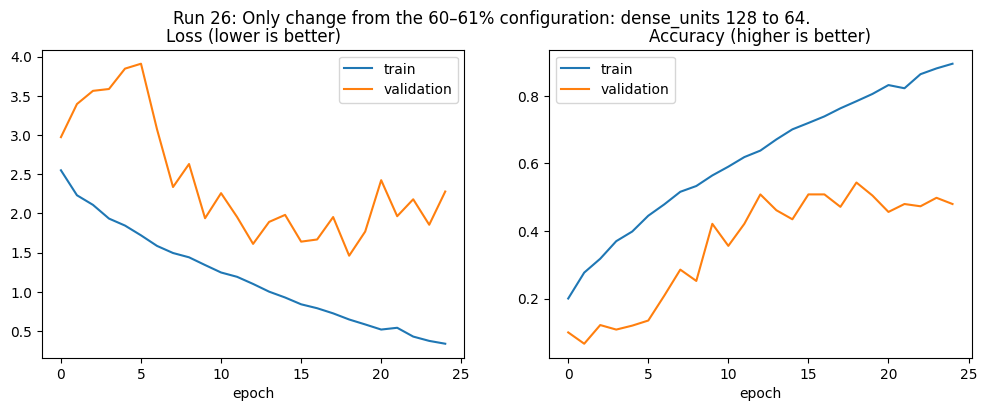

Run 26 | val_acc = 0.5435 | train_acc = 0.7838 | gap = 0.2404 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["base_filters"] = 64
cfg["dense_units"] = 64
cfg["dropout"] = 0.1



model = run_experiment(
    cfg,
    notes="Only change from the 60–61% configuration: dense_units 128 to 64."
)

Epoch 1/30
53/53 - 27s - 510ms/step - accuracy: 0.1946 - loss: 2.5853 - val_accuracy: 0.0602 - val_loss: 3.2699
Epoch 2/30
53/53 - 1s - 25ms/step - accuracy: 0.2737 - loss: 2.2428 - val_accuracy: 0.0753 - val_loss: 3.6007
Epoch 3/30
53/53 - 1s - 24ms/step - accuracy: 0.3155 - loss: 2.1221 - val_accuracy: 0.0836 - val_loss: 4.1655
Epoch 4/30
53/53 - 1s - 24ms/step - accuracy: 0.3565 - loss: 1.9689 - val_accuracy: 0.0936 - val_loss: 4.1071
Epoch 5/30
53/53 - 2s - 29ms/step - accuracy: 0.3993 - loss: 1.8789 - val_accuracy: 0.1689 - val_loss: 2.9203
Epoch 6/30
53/53 - 2s - 30ms/step - accuracy: 0.4533 - loss: 1.7143 - val_accuracy: 0.2826 - val_loss: 2.7747
Epoch 7/30
53/53 - 1s - 25ms/step - accuracy: 0.4907 - loss: 1.5858 - val_accuracy: 0.2174 - val_loss: 3.0599
Epoch 8/30
53/53 - 1s - 25ms/step - accuracy: 0.5388 - loss: 1.4310 - val_accuracy: 0.2993 - val_loss: 2.7900
Epoch 9/30
53/53 - 1s - 25ms/step - accuracy: 0.5579 - loss: 1.3552 - val_accuracy: 0.3311 - val_loss: 2.4908
Epoch 10

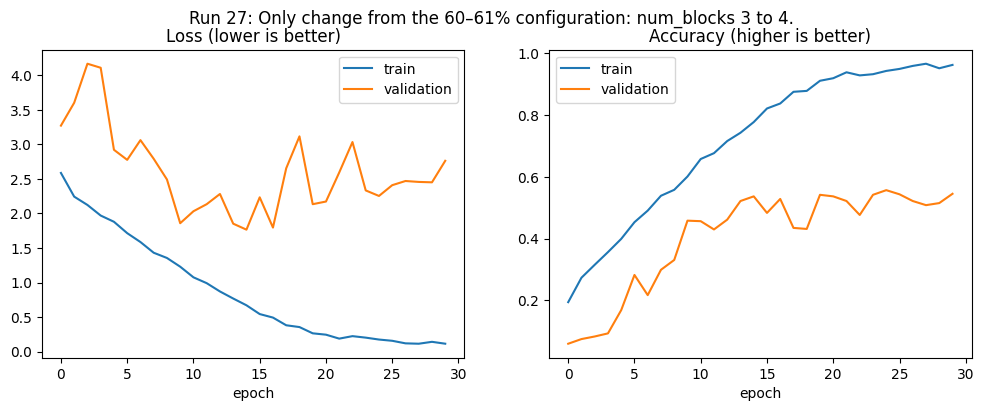

Run 27 | val_acc = 0.5569 | train_acc = 0.9425 | gap = 0.3856 | 1.1 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["base_filters"] = 64
cfg["dense_units"] = 128
cfg["dropout"] = 0.1
cfg["learning_rate"] = 0.001
cfg["augment"] = False
cfg["num_blocks"] = 4

model = run_experiment(
    cfg,
    notes="Only change from the 60–61% configuration: num_blocks 3 to 4."
)

Epoch 1/30
106/106 - 30s - 286ms/step - accuracy: 0.2156 - loss: 2.4844 - val_accuracy: 0.0803 - val_loss: 3.2663
Epoch 2/30
106/106 - 1s - 11ms/step - accuracy: 0.2799 - loss: 2.2354 - val_accuracy: 0.0719 - val_loss: 3.6920
Epoch 3/30
106/106 - 1s - 10ms/step - accuracy: 0.3265 - loss: 2.0777 - val_accuracy: 0.1237 - val_loss: 3.6081
Epoch 4/30
106/106 - 1s - 10ms/step - accuracy: 0.3698 - loss: 1.9463 - val_accuracy: 0.2375 - val_loss: 3.0325
Epoch 5/30
106/106 - 1s - 10ms/step - accuracy: 0.4064 - loss: 1.8285 - val_accuracy: 0.2977 - val_loss: 2.5329
Epoch 6/30
106/106 - 1s - 10ms/step - accuracy: 0.4527 - loss: 1.7103 - val_accuracy: 0.3294 - val_loss: 2.2766
Epoch 7/30
106/106 - 1s - 10ms/step - accuracy: 0.4881 - loss: 1.5811 - val_accuracy: 0.2475 - val_loss: 2.9616
Epoch 8/30
106/106 - 1s - 10ms/step - accuracy: 0.5173 - loss: 1.4978 - val_accuracy: 0.4181 - val_loss: 1.8814
Epoch 9/30
106/106 - 1s - 10ms/step - accuracy: 0.5302 - loss: 1.4134 - val_accuracy: 0.4398 - val_los

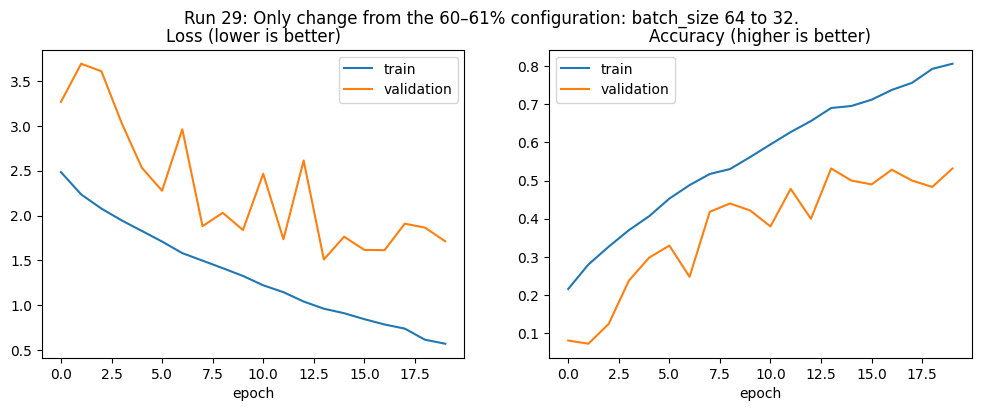

Run 29 | val_acc = 0.5318 | train_acc = 0.6904 | gap = 0.1586 | 0.8 min


In [ ]:
cfg = dict(baseline_cfg)
cfg.update({
    "base_filters": 64,
    "dense_units": 128,
    "dropout": 0.1,
    "learning_rate": 0.001,
    "augment": False,
    "num_blocks": 3,
    "batch_size": 32,
})

model = run_experiment(
    cfg,
    notes="Only change from the 60–61% configuration: batch_size 64 to 32."
)

Epoch 1/30
27/27 - 26s - 947ms/step - accuracy: 0.2117 - loss: 2.5230 - val_accuracy: 0.0903 - val_loss: 2.9194
Epoch 2/30
27/27 - 1s - 30ms/step - accuracy: 0.3105 - loss: 2.1590 - val_accuracy: 0.0468 - val_loss: 3.3023
Epoch 3/30
27/27 - 1s - 29ms/step - accuracy: 0.3480 - loss: 2.0344 - val_accuracy: 0.0970 - val_loss: 3.4522
Epoch 4/30
27/27 - 1s - 29ms/step - accuracy: 0.3795 - loss: 1.9033 - val_accuracy: 0.0920 - val_loss: 3.5271
Epoch 5/30
27/27 - 1s - 28ms/step - accuracy: 0.4261 - loss: 1.7690 - val_accuracy: 0.0920 - val_loss: 3.7774
Epoch 6/30
27/27 - 1s - 29ms/step - accuracy: 0.4680 - loss: 1.6565 - val_accuracy: 0.0803 - val_loss: 4.6074
Epoch 7/30
27/27 - 1s - 29ms/step - accuracy: 0.5108 - loss: 1.5217 - val_accuracy: 0.1020 - val_loss: 4.4266
Epoch 8/30
27/27 - 1s - 29ms/step - accuracy: 0.5320 - loss: 1.4076 - val_accuracy: 0.1438 - val_loss: 3.8174
Epoch 9/30
27/27 - 1s - 29ms/step - accuracy: 0.5712 - loss: 1.3209 - val_accuracy: 0.0753 - val_loss: 4.2826
Epoch 10

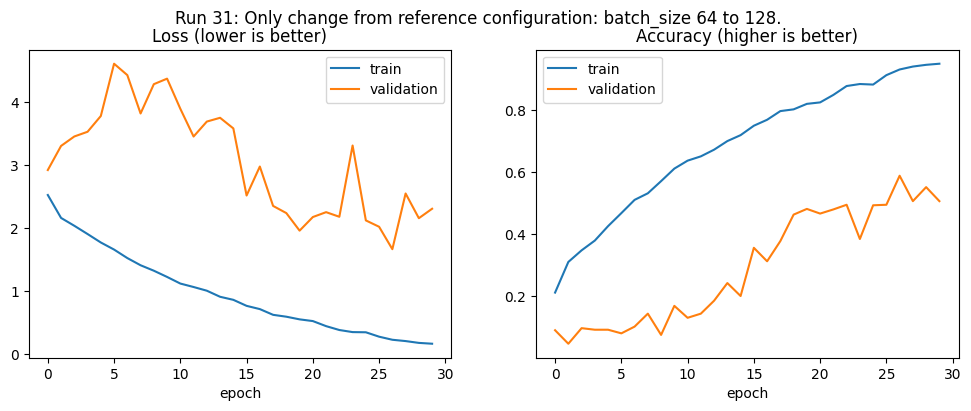

Run 31 | val_acc = 0.5886 | train_acc = 0.9313 | gap = 0.3427 | 0.8 min


In [ ]:
cfg = dict(baseline_cfg)
cfg.update({
    "base_filters": 64,
    "dense_units": 128,
    "dropout": 0.1,
    "batch_size": 128,
})

model = run_experiment(
    cfg,
    notes="Only change from reference configuration: batch_size 64 to 128."
)

Epoch 1/30
53/53 - 18s - 332ms/step - accuracy: 0.2088 - loss: 2.5168 - val_accuracy: 0.0719 - val_loss: 3.5242 - learning_rate: 0.0010
Epoch 2/30
53/53 - 1s - 18ms/step - accuracy: 0.2990 - loss: 2.1566 - val_accuracy: 0.0819 - val_loss: 3.5584 - learning_rate: 0.0010
Epoch 3/30
53/53 - 1s - 16ms/step - accuracy: 0.3574 - loss: 2.0040 - val_accuracy: 0.1104 - val_loss: 4.3734 - learning_rate: 0.0010
Epoch 4/30
53/53 - 1s - 16ms/step - accuracy: 0.4155 - loss: 1.7801 - val_accuracy: 0.0803 - val_loss: 4.2599 - learning_rate: 5.0000e-04
Epoch 5/30
53/53 - 1s - 18ms/step - accuracy: 0.4556 - loss: 1.6843 - val_accuracy: 0.0886 - val_loss: 4.0352 - learning_rate: 5.0000e-04
Epoch 6/30
53/53 - 1s - 25ms/step - accuracy: 0.5102 - loss: 1.5227 - val_accuracy: 0.1037 - val_loss: 3.9265 - learning_rate: 2.5000e-04
Epoch 7/30
53/53 - 1s - 17ms/step - accuracy: 0.5429 - loss: 1.4391 - val_accuracy: 0.1622 - val_loss: 3.8708 - learning_rate: 2.5000e-04
Epoch 8/30
53/53 - 1s - 17ms/step - accuracy

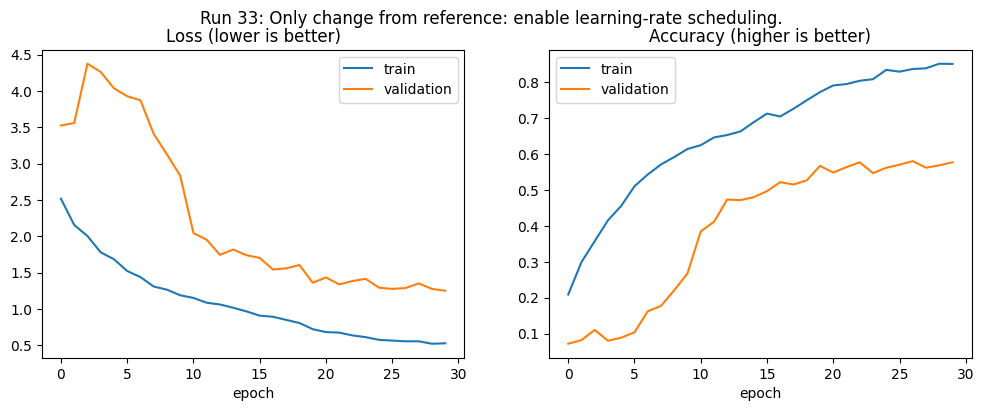

Run 33 | val_acc = 0.5803 | train_acc = 0.8366 | gap = 0.2564 | 0.7 min


In [ ]:
cfg = dict(baseline_cfg)
cfg.update({
    "base_filters": 64,
    "dense_units": 128,
    "dropout": 0.1,
    "batch_size": 64,
    "use_lr_schedule": True,
})

model = run_experiment(
    cfg,
    notes="Only change from reference: enable learning-rate scheduling."
)

Epoch 1/50
53/53 - 17s - 323ms/step - accuracy: 0.2259 - loss: 2.4661 - val_accuracy: 0.0803 - val_loss: 3.0709 - learning_rate: 0.0010
Epoch 2/50
53/53 - 1s - 18ms/step - accuracy: 0.2893 - loss: 2.1776 - val_accuracy: 0.0485 - val_loss: 3.4485 - learning_rate: 0.0010
Epoch 3/50
53/53 - 1s - 16ms/step - accuracy: 0.3368 - loss: 2.0355 - val_accuracy: 0.0786 - val_loss: 3.8613 - learning_rate: 0.0010
Epoch 4/50
53/53 - 1s - 17ms/step - accuracy: 0.4132 - loss: 1.8114 - val_accuracy: 0.0870 - val_loss: 3.8059 - learning_rate: 5.0000e-04
Epoch 5/50
53/53 - 1s - 16ms/step - accuracy: 0.4423 - loss: 1.7124 - val_accuracy: 0.0870 - val_loss: 3.6461 - learning_rate: 5.0000e-04
Epoch 6/50
53/53 - 1s - 17ms/step - accuracy: 0.5025 - loss: 1.5386 - val_accuracy: 0.1154 - val_loss: 3.6266 - learning_rate: 2.5000e-04
Epoch 7/50
53/53 - 1s - 17ms/step - accuracy: 0.5231 - loss: 1.4508 - val_accuracy: 0.1505 - val_loss: 3.3414 - learning_rate: 2.5000e-04
Epoch 8/50
53/53 - 1s - 17ms/step - accuracy

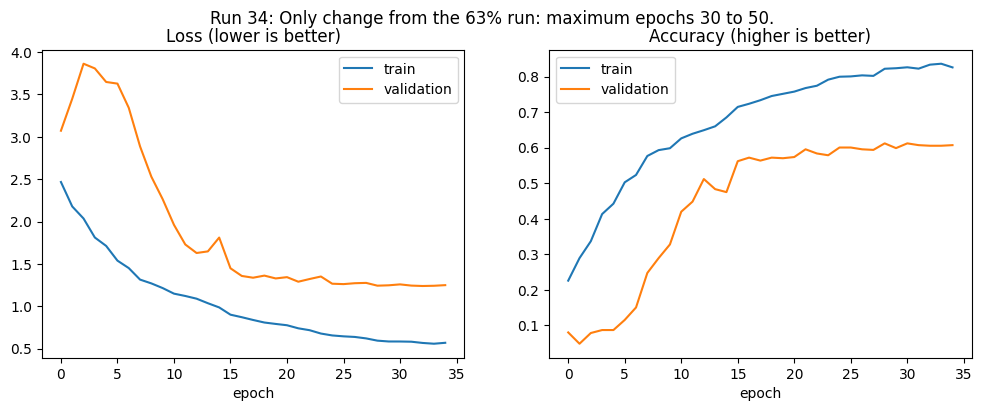

Run 34 | val_acc = 0.6120 | train_acc = 0.8219 | gap = 0.2098 | 0.8 min


In [ ]:
cfg = dict(baseline_cfg)
cfg.update({
    "base_filters": 64,
    "dense_units": 128,
    "dropout": 0.1,
    "batch_size": 64,
    "learning_rate": 0.001,
    "augment": False,
    "use_lr_schedule": True,
    "epochs": 50,
})

model = run_experiment(
    cfg,
    notes="Only change from the 63% run: maximum epochs 30 to 50."
)

## Step 6: Your results table

This is your lab notebook. Look for patterns: which settings help, which hurt, which hardly matter. Copy the most interesting rows into the table in your README or report, and write one sentence about what you learned from each.

,run,notes,learning_rate,batch_size,optimizer,dropout,l2,base_filters,num_blocks,dense_units,augment,use_lr_schedule,train_acc,val_acc,gap,best_epoch,minutes
0,32,Only change from reference: enable learning-ra...,0.0010,64,adam,0.10,0.0000,64,3,128,False,True,0.8844,0.6288,0.2556,29,0.7
1,19,"64 filters, 128 dense units: increase dropout ...",0.0010,64,adam,0.10,0.0000,64,3,128,False,False,0.8912,0.6120,0.2791,25,0.7
2,34,Only change from the 63% run: maximum epochs 3...,0.0010,64,adam,0.10,0.0000,64,3,128,False,True,0.8219,0.6120,0.2098,29,0.8
3,14,Compared with the 59% run: reduce dense_units ...,0.0010,64,adam,0.25,0.0000,64,3,128,False,False,0.7800,0.6054,0.1747,24,0.7
4,20,"64 filters, 128 dense units: increase dropout ...",0.0010,64,adam,0.10,0.0000,64,3,128,False,False,0.9366,0.6037,0.3329,30,0.7
5,21,"64 filters, 128 dense units: increase dropout ...",0.0010,64,adam,0.10,0.0000,64,3,128,False,False,0.8287,0.6003,0.2283,20,0.7
6,4,dropout to 0.05,0.0010,64,adam,0.25,0.0000,32,3,256,False,False,0.6830,0.5953,0.0877,23,0.5
7,10,"Only change: base_filters 32 to 64, testing wh...",0.0010,64,adam,0.25,0.0000,64,3,256,False,False,0.7824,0.5936,0.1887,25,0.9
8,5,dropout to 0.05,0.0010,64,adam,0.25,0.0000,32,3,256,False,False,0.7154,0.5903,0.1251,27,0.5
9,11,"Only change: base_filters 32 to 64, testing wh...",0.0010,64,adam,0.25,0.0000,64,3,128,False,False,0.7508,0.5886,0.1622,25,0.7


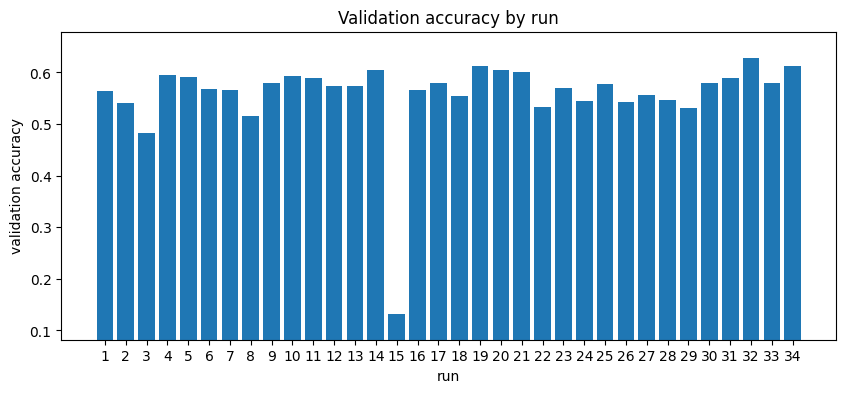

In [ ]:
log_df = pd.DataFrame(experiment_log)
shown = [c for c in ["run", "notes", "learning_rate", "batch_size", "optimizer", "dropout", "l2",
                     "base_filters", "num_blocks", "dense_units", "augment", "use_lr_schedule",
                     "train_acc", "val_acc", "gap", "best_epoch", "minutes"] if c in log_df.columns]
display(log_df[shown].sort_values("val_acc", ascending=False).reset_index(drop=True))

plt.figure(figsize=(10, 4))
plt.bar(log_df["run"].astype(str), log_df["val_acc"])
plt.xlabel("run"); plt.ylabel("validation accuracy"); plt.title("Validation accuracy by run")
plt.ylim(max(0, log_df["val_acc"].min() - 0.05), min(1, log_df["val_acc"].max() + 0.05))
plt.show()

In [ ]:
# Optional: download your log (and keep it safe, Colab deletes files when the session ends)
from google.colab import files
files.download("experiment_log.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 7: The final exam (run this ONCE)

When you are finished tuning, evaluate your best saved model on the test set. This tells you how well it will work on brand new images.

If you now go back and tune further because of this number, it stops being a fair test. So do this only when you are done.

In [ ]:
best_model = keras.models.load_model(BEST_MODEL_FILE)
test_loss, test_acc = best_model.evaluate(x_test, y_test, verbose=0)
print(f"Best validation accuracy during tuning: {best_val_so_far:.4f}")
print(f"FINAL TEST ACCURACY:                    {test_acc:.4f}")

# Which classes does the model handle best and worst?
preds = np.argmax(best_model.predict(x_test, verbose=0), axis=1)
per_class = pd.Series({CLASS_NAMES[c]: float(np.mean(preds[y_test == c] == c)) for c in range(NUM_CLASSES)}).sort_values()
print("\nHardest classes:\n", per_class.head(5).round(2).to_string())
print("\nEasiest classes:\n", per_class.tail(5).round(2).to_string())

Best validation accuracy during tuning: 0.6288
FINAL TEST ACCURACY:                    0.6392

Hardest classes:
 snail           0.36
sweet_pepper    0.47
clock           0.47
shark           0.50
lobster         0.53

Easiest classes:
 apple         0.76
forest        0.78
dolphin       0.82
skyscraper    0.84
orange        0.93


## Reflection questions

Write short answers in a text cell or in your report:

1. Which single change gave the biggest improvement? Why do you think it helped?
2. Did any change make results worse? What does that teach you?
3. Look at the `gap` column. When was your model overfitting the most?
4. How different were your validation and test accuracy? What would a very large difference mean?
5. If you had two more hours, what would you try next?

1) the biggest change which made a huge improvement was base_filters from 32 to 64 more filters gives the model to learn a wide variety of features so i think that is why its accuracy increased

2. yeah actually many parameter changes made worse that tells me more complexity wont help with models accuarcy.

3. yes the gap column was huge in run 19 that was around 27 percent

4. my validation accuracy was around 62.88 percent and test accuracy was around 63.92 .  A very huge difference would overfitting to validation set and unrelaible for evaluation.

5. I would keep the best configuration unchanged and train it several more times to check whether its validation accuracy is consistently high or whether the best result was a lucky run